# Energy and force pretraining validation

Run 02-EF-Pretrain-TensorBackbone-9246027. Validation review, 4 November 2026.

In [1]:
run_id = '02-EF-Pretrain-TensorBackbone-9246027'

from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from graph_pes.config.shared import instantiate_config_from_dict, parse_loss
from graph_pes.config.training import TrainingConfig

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(root))
import nmr_helpers  # Register custom models and losses.

torch.set_num_threads(2)
torch.set_default_dtype(torch.float32)
run = root / 'graph-pes-results' / run_id
config = yaml.safe_load((run / 'train-config.yaml').read_text())
valid = config['data']['valid']
frames = read(root / valid['path'], index=':')
assert len(frames) == 50

def load(path):
    return torch.load(path, map_location='cpu', weights_only=False)

model = load(run / 'model.pt').eval()
ckpts = {name: load(run / 'checkpoints' / f'{name}.ckpt') for name in ('best', 'last')}
states = {name: {key[6:]: value for key, value in ckpt['state_dict'].items()
                 if key.startswith('model.')} for name, ckpt in ckpts.items()}
assert model.state_dict().keys() == states['best'].keys()
for key, value in model.state_dict().items():
    if torch.is_tensor(value):
        torch.testing.assert_close(value, states['best'][key], rtol=0, atol=0)

stop = next(value for key, value in ckpts['last']['callbacks'].items()
            if key.startswith('EarlyStopping'))
improvements = np.array([float(value) for value in re.findall(
    r'New best model: validation loss ([0-9.eE+-]+)', (run/'rank-0.log').read_text())])
assert np.isclose(improvements[-1], stop['best_val_loss'])
lr = ckpts['last']['optimizer_states'][0]['param_groups'][0]['lr']
print(f"Validation: {valid['path']}, {len(frames)} structures, {sum(map(len, frames)):,} atoms.")
print(f"Final learning rate: {lr:.6g}. Checks since best: {stop['wait_count']}/{stop['patience']}.")
print("Exported model tensor state matches best.ckpt exactly.")

Validation: data/valid.xyz, 50 structures, 7,200 atoms.
Final learning rate: 0.003. Checks since best: 1/300.
Exported model tensor state matches best.ckpt exactly.


In [2]:
mapping = valid['property_map']
graphs = [AtomicGraph.from_ase(atoms, cutoff=float(model.cutoff), property_mapping=mapping)
          for atoms in frames]
properties = list(mapping.values())
_, fit_config = instantiate_config_from_dict(config, TrainingConfig)
loss_fn = parse_loss(fit_config.loss)
predictions, losses = {}, {}
for name, state in states.items():
    model.load_state_dict(state, strict=True)
    predictions[name] = {key: [] for key in properties}
    frame_losses = []
    for graph in graphs:
        # Force prediction differentiates energy with respect to positions.
        with torch.set_grad_enabled('forces' in properties):
            predicted = model.predict(graph, properties)
        for key, tensor in predicted.items():
            assert torch.isfinite(tensor).all()
            assert tensor.shape == graph.properties[key].shape
            predictions[name][key].append(tensor.detach().cpu().numpy())
        with torch.no_grad():
            frame_losses.append(float(loss_fn(model, graph, predicted).loss_value))
    losses[name] = float(np.mean(frame_losses))

checkpoint_table = pd.DataFrame([
    {'Checkpoint': name, 'Epoch (1-based)': ckpt['epoch'] + 1,
     'Optimiser updates': ckpt['global_step'], 'Validation loss (CPU)': losses[name]}
    for name, ckpt in ckpts.items()
])
print(checkpoint_table.to_string(index=False, float_format=lambda x: f'{x:.6f}'))
gap = 100 * abs(losses['best'] / stop['best_val_loss'] - 1)
print(f"Best loss recorded on ARC: {stop['best_val_loss']:.6f}. CPU difference: {gap:.3f}%.")

Checkpoint  Epoch (1-based)  Optimiser updates  Validation loss (CPU)
      best               43               8600               0.321032
      last               44               8800               0.797759
Best loss recorded on ARC: 0.320426. CPU difference: 0.189%.


## Training progress

The best checkpoint was at epoch 43 of 44 saved epochs. The learning rate was still 0.003, and early stopping had counted 1 of 300 checks without improvement. Convergence is unestablished. The copied log ends during best-weight loading and gives no termination reason.

The copied log lists new validation minima without epoch numbers. The plot counts these improvements. The checkpoint table gives the known epochs.

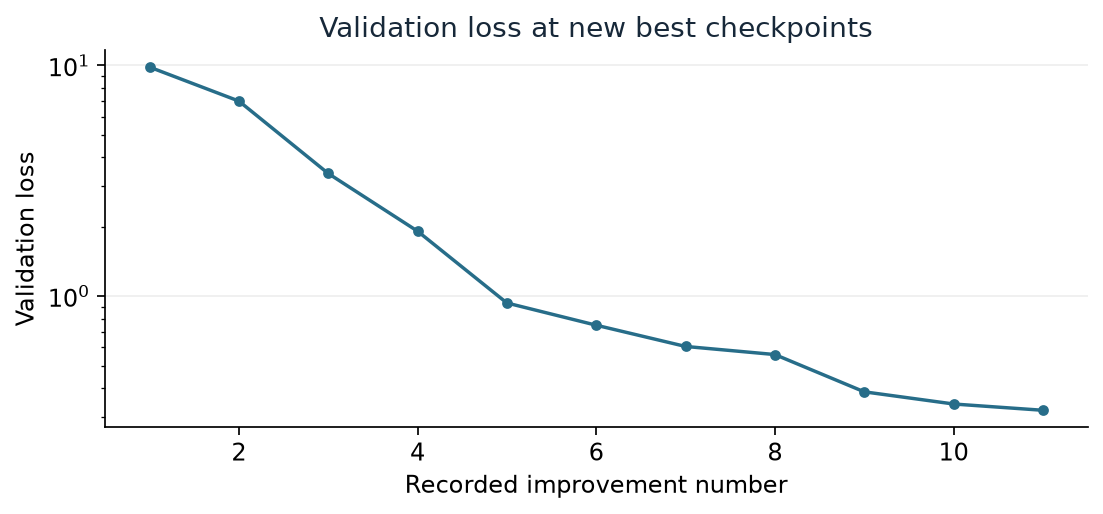

In [3]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'text.color': '#172839'})
fig, ax = plt.subplots(figsize=(7, 3.2), layout='constrained')
ax.plot(np.arange(1, len(improvements) + 1), improvements, 'o-', ms=4, lw=1.6, color='#276d89')
ax.set(yscale='log', xlabel='Recorded improvement number',
       ylabel='Validation loss', title='Validation loss at new best checkpoints')
ax.grid(axis='y', alpha=0.22)
plt.show()

## Validation parity

Energy parity uses one value per structure in meV/atom, with the same mean DFT energy per atom subtracted from both axes. This translation preserves all three metrics. Force parity pools signed x, y and z components across atoms. R² is 1 − SSE/SST over the reference values in each panel.

In [4]:
atom_counts = np.array([len(a) for a in frames])
energy = np.array([a.info['QM_energy'] for a in frames], dtype=np.float64)
force = np.concatenate([a.arrays['QM_forces'] for a in frames]).astype(np.float64).ravel()
energy_per_atom = 1000 * energy / atom_counts
energy_reference = energy_per_atom.mean()

def panel_data(name):
    predicted_energy = np.array(predictions[name]['energy'], dtype=np.float64).reshape(-1)
    predicted_forces = np.concatenate(predictions[name]['forces']).astype(np.float64).ravel()
    return [
        ('Energy per atom', 'meV/atom', energy_per_atom - energy_reference,
         1000 * predicted_energy / atom_counts - energy_reference),
        ('Force components', 'eV/Å', force, predicted_forces),
    ]

def metrics(reference, prediction):
    residual = prediction - reference
    return {'N': reference.size, 'RMSE': np.sqrt(np.mean(residual**2)),
            'MAE': np.mean(np.abs(residual)),
            'R²': 1 - np.sum(residual**2) / np.sum((reference - reference.mean())**2)}

records = [{'Checkpoint': name, 'Quantity': title, 'Units': units, **metrics(reference, prediction)}
           for name in ckpts for title, units, reference, prediction in panel_data(name)]
print(pd.DataFrame(records).to_string(index=False, float_format=lambda x: f'{x:.4f}'))

Checkpoint         Quantity    Units     N   RMSE    MAE     R²
      best  Energy per atom meV/atom    50 2.0971 1.7395 0.9996
      best Force components     eV/Å 21600 0.0563 0.0321 0.9985
      last  Energy per atom meV/atom    50 9.0539 7.8782 0.9933
      last Force components     eV/Å 21600 0.0846 0.0575 0.9966


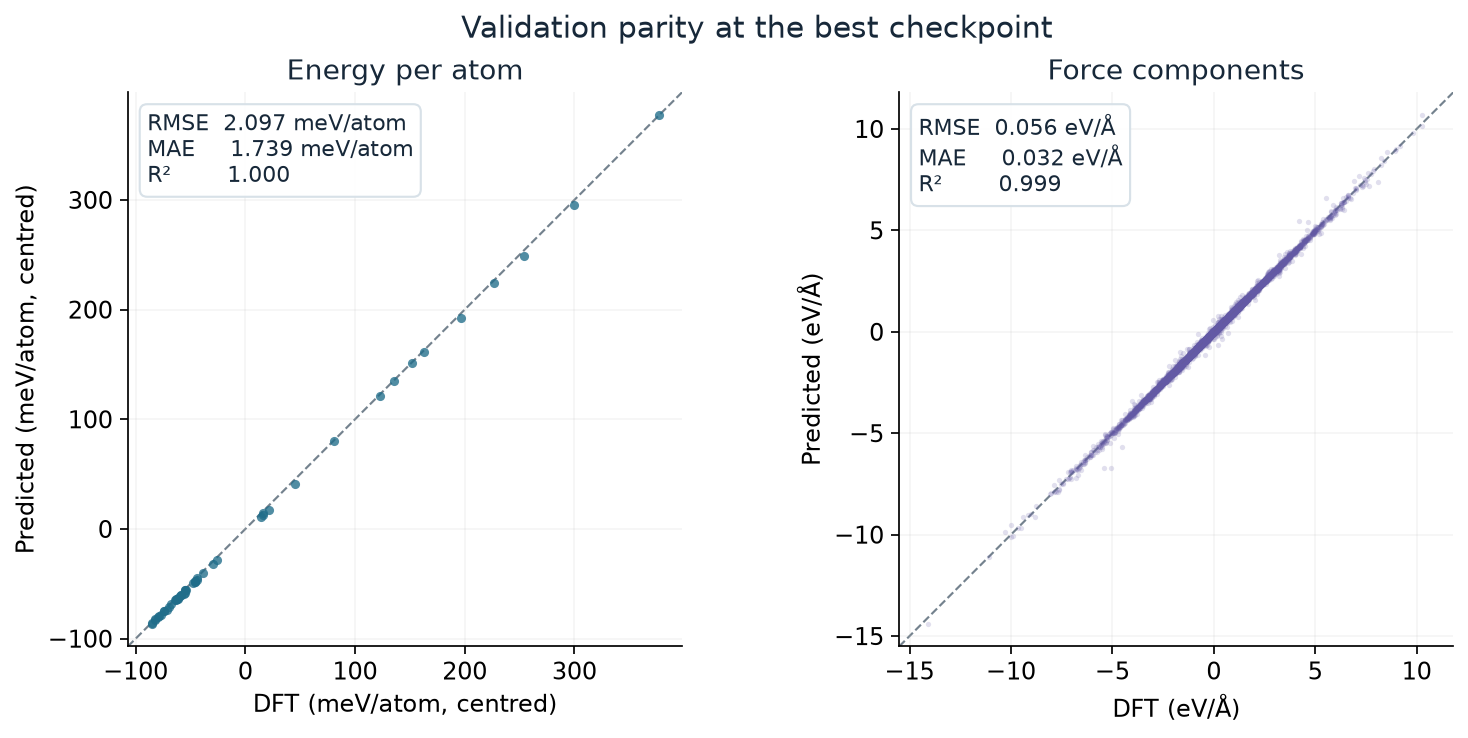

In [5]:
panels = panel_data('best')
nrows = len(panels) // 2
fig, axes = plt.subplots(nrows, 2, figsize=(10, 4.65 * nrows), squeeze=False, layout='constrained')
colors = ['#206d8a', '#6359a5', '#c16335', '#3a8064']
for idx, (ax, (title, units, reference, predicted)) in enumerate(zip(axes.flat, panels)):
    paired = [panels[idx % 2], panels[idx % 2 + 2]] if nrows == 2 else [panels[idx]]
    low = min(min(p[2].min(), p[3].min()) for p in paired)
    high = max(max(p[2].max(), p[3].max()) for p in paired)
    pad = 0.045 * (high - low)
    limits = (low - pad, high + pad)
    ax.plot(limits, limits, '--', lw=1, color='#74828e', zorder=1)
    ax.scatter(reference, predicted, s=18 if reference.size <= 50 else 6,
               alpha=0.78 if reference.size <= 50 else 0.19,
               color=colors[idx], linewidths=0, zorder=2)
    axis_units = 'meV/atom, centred' if units == 'meV/atom' else units
    ax.set(xlim=limits, ylim=limits, title=title,
           xlabel=f'DFT ({axis_units})', ylabel=f'Predicted ({axis_units})')
    ax.set_aspect('equal', adjustable='box')
    m = metrics(reference, predicted)
    ax.text(0.035, 0.965, f"RMSE  {m['RMSE']:.3f} {units}\n"
                         f"MAE     {m['MAE']:.3f} {units}\n"
                         f"R²        {m['R²']:.3f}",
            transform=ax.transAxes, va='top', fontsize=10, zorder=3,
            bbox=dict(facecolor='white', edgecolor='#d6e0e7', alpha=0.94, boxstyle='round,pad=0.35'))
    ax.grid(alpha=0.13, zorder=0)
fig.suptitle('Validation parity at the best checkpoint', fontsize=14)
plt.show()

At epoch 43, energy RMSE was 2.10 meV/atom (R² 0.9996) and force-component RMSE was 0.0563 eV/Å (R² 0.9985). The parity labels round R² to three decimal places.

At epoch 44, energy RMSE rose to 9.05 meV/atom and force-component RMSE to 0.0846 eV/Å. The weighted validation loss rose from 0.3210 to 0.7978, about 2.49×. Epoch 43 is the stronger saved E/F checkpoint. A matched comparison against the tensor scratch baseline would measure its value for NMR transfer.

## Held-out test set

Evaluate the epoch 43 checkpoint selected by validation loss on the 150 test structures in data/test.xyz. Energy error is per atom and force error is pooled over the three signed Cartesian components, matching the validation evaluation. The split manifest covers the training and validation pool. Test separation is checked by comparing stored geometries.

In [6]:
from hashlib import sha256
from time import perf_counter
from ase.io import iread

test_frames = read(root / 'data/test.xyz', index=':')
assert len(test_frames) == 150

def geometry_key(atoms):
    # Compare coordinates and cell to 6 decimal places in the stored atom order.
    geometry = np.concatenate([atoms.cell.array.ravel(), atoms.positions.ravel()])
    coordinates = np.rint(1e6 * geometry).astype('<i8')
    return sha256(atoms.numbers.astype('<i8').tobytes()
                  + atoms.pbc.tobytes() + coordinates.tobytes()).digest()

test_keys = {geometry_key(a) for a in test_frames}
for split in ('train', 'valid'):
    count = sum(geometry_key(a) in test_keys for a in iread(root / f'data/{split}.xyz', index=':'))
    print(f'Test geometry matches in {split} (stored atom order, 10⁻⁶ Å rounding): {count}.')

torch.set_num_threads(4)
model.load_state_dict(states['best'], strict=True)
model.eval()
# Only the position gradient is needed to calculate forces.
parameter_flags = [p.requires_grad for p in model.parameters()]
model.requires_grad_(False)
test_energy_prediction, test_force_prediction = [], []
start = perf_counter()
try:
    for i, atoms in enumerate(test_frames, 1):
        graph = AtomicGraph.from_ase(atoms, cutoff=float(model.cutoff), property_mapping=valid['property_map'])
        with torch.enable_grad():
            predicted = model.predict(graph, ['energy', 'forces'])
        assert predicted['forces'].shape == (len(atoms), 3)
        assert all(torch.isfinite(v).all() for v in predicted.values())
        test_energy_prediction.append(float(predicted['energy']) * 1000 / len(atoms))
        test_force_prediction.append(predicted['forces'].detach().numpy())
        if i == 1 or i % 25 == 0:
            print(f'Scored {i}/{len(test_frames)} structures ({perf_counter() - start:.0f} s).')
finally:
    for parameter, flag in zip(model.parameters(), parameter_flags):
        parameter.requires_grad_(flag)

test_energy = np.array([1000 * a.info['QM_energy'] / len(a) for a in test_frames])
test_forces = np.concatenate([a.arrays['QM_forces'] for a in test_frames]).astype(np.float64)
test_energy_prediction = np.array(test_energy_prediction)
test_force_prediction = np.concatenate(test_force_prediction).astype(np.float64)
energy_centre = test_energy.mean()
test_panels = [
    ('Energy per atom', 'meV/atom', test_energy - energy_centre, test_energy_prediction - energy_centre),
    ('Force components', 'eV/Å', test_forces.ravel(), test_force_prediction.ravel()),
]
test_records = [{'Split': 'Test', 'Quantity': title, 'Units': units,
                 **metrics(reference, prediction)} for title, units, reference, prediction in test_panels]
validation_records = [{'Split': 'Validation', **{k: v for k, v in r.items() if k != 'Checkpoint'}}
                      for r in records if r['Checkpoint'] == 'best']
comparison = pd.DataFrame(validation_records + test_records).sort_values('Quantity', kind='stable')
print(comparison.to_string(index=False, float_format=lambda x: f'{x:.5f}'))

Test geometry matches in train (stored atom order, 10⁻⁶ Å rounding): 0.
Test geometry matches in valid (stored atom order, 10⁻⁶ Å rounding): 0.
Scored 1/150 structures (4 s).
Scored 25/150 structures (112 s).
Scored 50/150 structures (236 s).
Scored 75/150 structures (353 s).
Scored 100/150 structures (484 s).
Scored 125/150 structures (612 s).
Scored 150/150 structures (738 s).
     Split         Quantity    Units     N    RMSE     MAE      R²
Validation  Energy per atom meV/atom    50 2.09711 1.73946 0.99964
      Test  Energy per atom meV/atom   150 2.16130 1.81721 0.99936
Validation Force components     eV/Å 21600 0.05627 0.03209 0.99852
      Test Force components     eV/Å 64800 0.04401 0.02840 0.99886


The test DFT mean energy per atom is subtracted from both energy axes. This changes the displayed origin while preserving the errors and R².

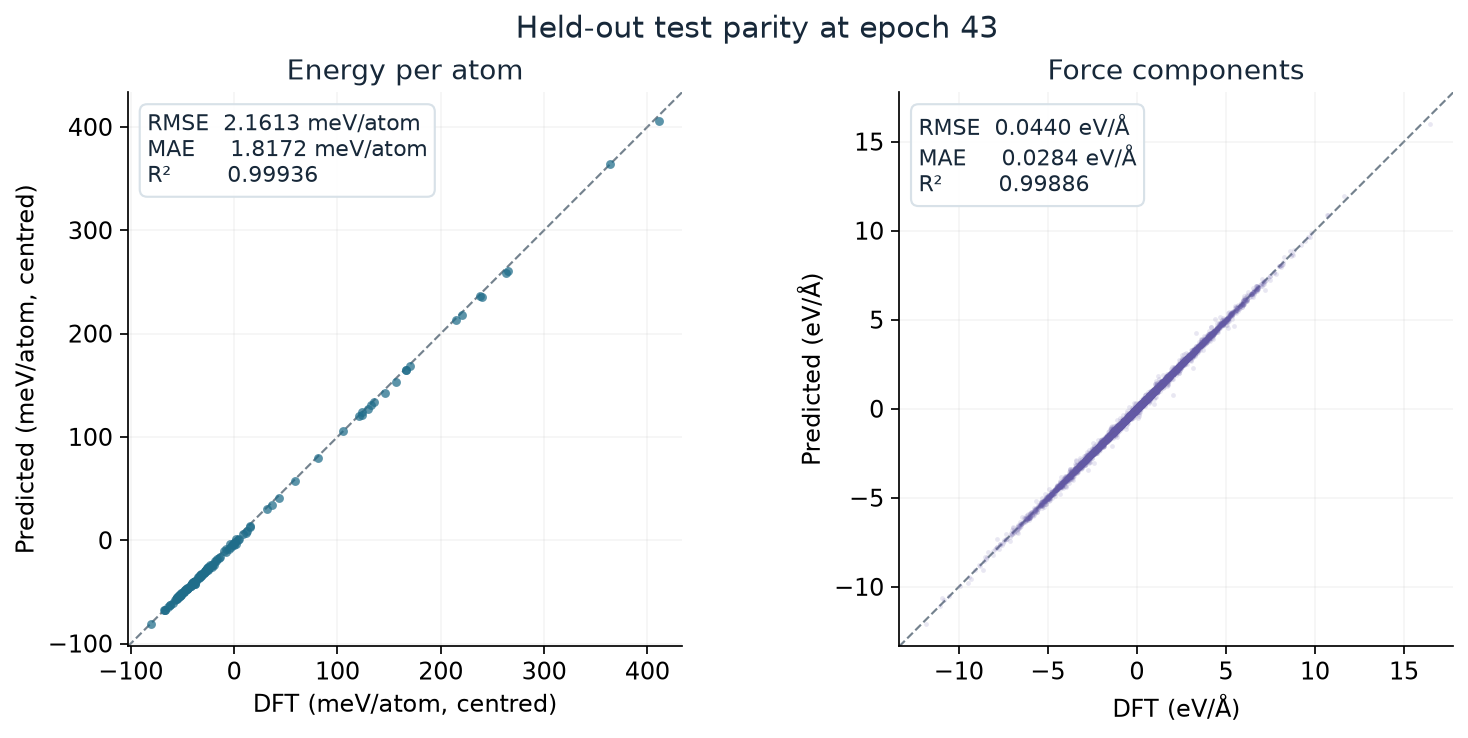

In [7]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'text.color': '#172839'})
fig, axes = plt.subplots(1, 2, figsize=(10, 4.65), layout='constrained')
for ax, (title, units, reference, prediction), color in zip(axes, test_panels, ['#206d8a', '#6359a5']):
    low, high = min(reference.min(), prediction.min()), max(reference.max(), prediction.max())
    pad = 0.045 * (high - low)
    limits = low - pad, high + pad
    ax.plot(limits, limits, '--', lw=1, color='#74828e', zorder=1)
    energy_panel = units == 'meV/atom'
    ax.scatter(reference, prediction, s=17 if energy_panel else 5,
               alpha=0.73 if energy_panel else 0.14, color=color, linewidths=0, zorder=2)
    label = 'meV/atom, centred' if energy_panel else units
    ax.set(xlim=limits, ylim=limits, title=title,
           xlabel=f'DFT ({label})', ylabel=f'Predicted ({label})')
    ax.set_aspect('equal', adjustable='box')
    m = metrics(reference, prediction)
    ax.text(0.035, 0.965, f"RMSE  {m['RMSE']:.4f} {units}\n"
                         f"MAE     {m['MAE']:.4f} {units}\n"
                         f"R²        {m['R²']:.5f}",
            transform=ax.transAxes, va='top', fontsize=10, zorder=3,
            bbox=dict(facecolor='white', edgecolor='#d6e0e7', alpha=0.94, boxstyle='round,pad=0.35'))
    ax.grid(alpha=0.13, zorder=0)
fig.suptitle('Held-out test parity at epoch 43', fontsize=14)
plt.show()

Test RMSE is **2.1613 meV/atom (3.1% higher than validation)** for energy per atom and **0.0440 eV/Å (21.8% lower than validation)** for force components. The geometry check detects exact repeats in the stored atom order. It does not establish independence of parent trajectories or performance on new materials.